# 21 - Series solutions

**MATH 331 - Differential Equations.** Lecture plan, Units 12 and 13: Session 27 (Sections 2-4) and
Session 28 (Sections 5-7).

**References:** J. Lebl, *Notes on Diffy Qs*, Sections 7.1-7.3 and the exercises of Chapter 7; W. E.
Boyce and R. C. DiPrima, *Elementary Differential Equations and Boundary Value Problems*, Theorems 5.3.1
and 5.6.1; notebooks 05E and 06.

**What you will learn**
1. When no formula for a solution is known, it can be written as a power series whose coefficients follow
   from a recurrence; the series is good inside a radius that the equation itself announces.
2. At a regular singular point a power $x^r$ in front of the series is needed, and $r$ comes from a
   quadratic, the indicial equation, whose kinds of roots are the cases of notebook 06 again.

## 1. Before you start

**What you need.** From calculus: Taylor series, such as $e^x = 1 + x + \frac{x^2}{2!} + \frac{x^3}{3!} +
\cdots$ (Lebl, Section 7.1.3). The sigma notation: $\sum_{k=0}^{3} a_kx^k$ means "add $a_kx^k$ for
$k = 0, 1, 2, 3$", that is $a_0 + a_1x + a_2x^2 + a_3x^3$; $k$ is only a counter. From notebook 06: the
characteristic equation, its three cases, and Euler's formula $e^{i\theta} = \cos\theta + i\sin\theta$.

**Conventions (the whole notebook).**
* $x$ is the independent variable (in the code, SymPy's letter `x`).
* A **power series** centered at $x_0$ is
  $\sum_{k=0}^{\infty} a_k(x - x_0)^k = a_0 + a_1(x - x_0) + \cdots$, with **coefficients** $a_k$; here
  mostly $x_0 = 0$. A **term** is an $a_kx^k$ that is not 0: "5 terms" of $1 - x^2 + x^4 - \cdots$ are
  $1 - x^2 + x^4 - x^6 + x^8$.
* $\rho$ ("rho") is the radius of convergence. An equation is $P(x)y'' + Q(x)y' + R(x)y = 0$ (Lebl writes
  $p$, $q$, $r$); $p_0$, $q_0$ are two limits and $r$ an exponent (Section 5); $\nu$ ("nu") is the order
  of Bessel's equation (Lebl's $p$).
* Python writes `j` for the complex unit $i$: `1.7725j` is $1.7725\,i$.

In [1]:
# --- Setup ---------------------------------------------------------------------
# odelib.py lives next to the notebooks: it contains the tested helper functions
# (here: series_coefficients, series_value, indicial_roots, check, check_formula, check_choice).
import sys
import pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp                      # noqa: F401  (not used in every notebook)
from IPython.display import Math, display                 # noqa: F401
from ipywidgets import FloatSlider, IntSlider, interact    # noqa: F401

import odelib as ol

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "font.size": 11, "legend.fontsize": 9})
print("numpy", np.__version__, "| sympy", sp.__version__)

numpy 2.5.4 | sympy 1.14.0


In [2]:
# SymPy's letter x, for formulas (arrays of numbers have their own names: points, grid, ...);
# and SciPy's special functions: the Airy functions and the Bessel functions J and Y (notebook 05E)
import numbers

from scipy.special import airy, jn_zeros, jv, yv

x = sp.symbols("x")
ROUNDING = 1e-15                            # an error below this is below the computer's rounding


def error_text(error):
    # an error as it is printed: "below 1e-15" rather than a 0 that would look exact
    return f"below {ROUNDING:.0e}" if error < ROUNDING else f"{error:.1e}"


# helpers of the checks of the exercises (Section 8): you can skip reading them
def larger_first(value):
    # two numbers in either order are the same answer: the larger is put first; anything else is left alone
    try:
        two_numbers = len(value) == 2 and all(
            isinstance(item, numbers.Real) and not isinstance(item, bool) for item in value)
        if two_numbers:
            return sorted(value, reverse=True)
    except TypeError:
        pass
    return value


def close_to(value, target):
    # True when value is a number, or a list of numbers, close to target (text and True/False are not)
    try:
        return (not isinstance(value, (str, bytes, bool)) and np.shape(value) == np.shape(target)
                and bool(np.allclose(np.asarray(value, dtype=complex), target)))
    except (TypeError, ValueError):
        return False


def same_numbers(value, targets):
    # True when value holds the same numbers as targets, real or complex, in any order
    try:
        mine = np.sort_complex(np.asarray(value, dtype=complex).ravel())
        return (not isinstance(value, (str, bytes)) and mine.shape == np.shape(targets)
                and bool(np.allclose(mine, np.sort_complex(np.asarray(targets, dtype=complex)))))
    except (TypeError, ValueError):
        return False


class WithoutOl:
    # stands for a name of the four cases written without "ol." in front (Exercise 1(d))
    def __init__(self, name):
        self.name = name

    def __repr__(self):
        return f"{self.name} (without ol.)"


CASE_NAMES = ("INDICIAL_NOT_INTEGER", "INDICIAL_DOUBLE", "INDICIAL_INTEGER", "INDICIAL_COMPLEX")
INDICIAL_NOT_INTEGER, INDICIAL_DOUBLE, INDICIAL_INTEGER, INDICIAL_COMPLEX = (
    WithoutOl(name) for name in CASE_NAMES)


def misspelt_case_hint(result):
    # under the red message of a misspelt ol.INDICIAL_... name (Exercise 1(d)): the four names
    error = getattr(result, "error_in_exec", None)
    if isinstance(error, AttributeError) and "INDICIAL_" in str(error):
        print(ol.HINT_LABEL + "the four names are " + ", ".join("ol." + name for name in CASE_NAMES)
              + ": copy one from the table of Section 5", file=sys.stderr)


try:
    shell = get_ipython()                   # in a notebook (not in plain Python): add this hint once
    if not getattr(shell, "_math331_case_hint", False):
        shell.events.register("post_run_cell", misspelt_case_hint)
        shell._math331_case_hint = True
except NameError:
    pass

## 2. Power series, a refresher

(Session 27.) *In class:* partial sums, the radius, slider 1; Section 3 up to the computer's
coefficients; Section 4 up to its figure. *At home:* the cells marked "(At home.)", and Section 9.

**A series is a limit of sums.** A computer can add only finitely many terms. The sum of the first $N$
terms is a **partial sum** (Lebl, Section 7.1.1). The series **converges** at $x$ when the
partial sums settle on one number as $N$ grows. Two series that you know:

$$ e^x = 1 + x + \frac{x^2}{2!} + \frac{x^3}{3!} + \cdots, \qquad
   \frac{1}{1 - x} = 1 + x + x^2 + x^3 + \cdots \ \text{(the geometric series).} $$

`ol.series_value(coefficients, x)` adds $a_0 + a_1x + a_2x^2 + \cdots$ for the coefficients it is given.
The table adds the first $N$ terms of each series at $x = 0.5$ and at $x = 1.5$.

In [3]:
from math import factorial

N_SHOWN = (1, 2, 3, 5, 10, 20)              # numbers of terms
X_SHOWN = (0.5, 1.5)                        # try others (1/(1 - x) is not defined at x = 1)
exp_coefficients = np.array([1 / factorial(k) for k in range(max(N_SHOWN))])     # a_k = 1/k!
geometric_coefficients = np.ones(max(N_SHOWN))                                  # a_k = 1
for x_value in X_SHOWN:
    print(f"x = {x_value:g}:  N   e^x by N terms   1/(1 - x) by N terms")
    for n in N_SHOWN:
        print(f"{n:11d} {float(ol.series_value(exp_coefficients[:n], x_value)):16.6f} "
              f"{float(ol.series_value(geometric_coefficients[:n], x_value)):22.6f}")
    function_value = "not defined" if x_value == 1 else f"{1 / (1 - x_value):.6f}"
    print(f"the functions: e^x = {np.exp(x_value):.6f}, 1/(1 - x) = {function_value}")
    print()

x = 0.5:  N   e^x by N terms   1/(1 - x) by N terms
          1         1.000000               1.000000
          2         1.500000               1.500000
          3         1.625000               1.750000
          5         1.648438               1.937500
         10         1.648721               1.998047
         20         1.648721               1.999998
the functions: e^x = 1.648721, 1/(1 - x) = 2.000000

x = 1.5:  N   e^x by N terms   1/(1 - x) by N terms
          1         1.000000               1.000000
          2         2.500000               2.500000
          3         3.625000               4.750000
          5         4.398438              13.187500
         10         4.481671             113.330078
         20         4.481689            6648.513460
the functions: e^x = 4.481689, 1/(1 - x) = -2.000000



*The table shows* that at $x = 0.5$ both columns settle: on $1.648721 = e^{0.5}$ and on $2 = 1/(1 - 0.5)$.
At $x = 1.5$ the series of $e^x$ settles on $e^{1.5} = 4.481689$, but the geometric one does not: 4.75,
13.19, 113.3, 6649. It **diverges**, although $1/(1 - x)$ is a good number there, $-2$. In Lebl's words,
"a series for a function only defines the function on an interval" (Section 7.1.5).

So there are three questions. Does the series **converge** (do the partial sums settle)? Does it **agree
with the function** (is that number the function's value)? And, for the computer: **how many terms** give
the accuracy we want? Here the first two answers are yes inside the radius (defined below) and the first is
no outside it; the third can be "many" even inside (Section 6).

**The radius of convergence.** For every power series there is a number $\rho$ (maybe $\infty$): the
series converges for $|x - x_0| < \rho$ and diverges for $|x - x_0| > \rho$ (Lebl, Theorem 7.1.1). For
$e^x$, $\rho = \infty$; for the geometric series, $\rho = 1$.

(At home.) **The ratio test** finds $\rho$ (Lebl, Theorem 7.1.2, in another form). Compare a term with
the next one that is not 0: if $\left|\dfrac{\text{next term}}{\text{this term}}\right|$ tends to a limit
$L$ as $k$ grows, the series converges where $L < 1$ and diverges where $L > 1$. For $e^x$:
$\left|\dfrac{x^{k+1}/(k + 1)!}{x^k/k!}\right| = \dfrac{|x|}{k + 1}$ (since $\frac{k!}{(k + 1)!} =
\frac{1}{k + 1}$), which tends to 0 for every $x$: $\rho = \infty$. For the geometric series the quotient
is $|x|$, below 1 exactly for $|x| < 1$: $\rho = 1$. The cell prints $|a_{k+1}/a_k|$, the number by
which $|x|$ is multiplied.

In [4]:
RATIO_STEP = 4                              # every 4th k is printed
print(" k   e^x: |a_(k+1) / a_k|   geometric: |a_(k+1) / a_k|")
for k in range(0, max(N_SHOWN) - 1, RATIO_STEP):
    print(f"{k:2d} {exp_coefficients[k + 1] / exp_coefficients[k]:20.4f} "
          f"{geometric_coefficients[k + 1] / geometric_coefficients[k]:27.4f}")

 k   e^x: |a_(k+1) / a_k|   geometric: |a_(k+1) / a_k|
 0               1.0000                      1.0000
 4               0.2000                      1.0000
 8               0.1111                      1.0000
12               0.0769                      1.0000
16               0.0588                      1.0000


**Slider 1: a series that stops for no visible reason.** The function $\dfrac{1}{1 + x^2}$ is defined and
smooth for every real $x$, and its series is

$$ \frac{1}{1 + x^2} = 1 - x^2 + x^4 - x^6 + \cdots $$

The slider sets the number $N$ of terms; the plot shows the partial sum and the function for
$-2 \le x \le 2$, and the title gives the error at $x = 0.5$ and at $x = 1.5$. Before moving it: the
series uses only real numbers, and the function has no problem anywhere on the real line. Where does the
series stop working, and why there?

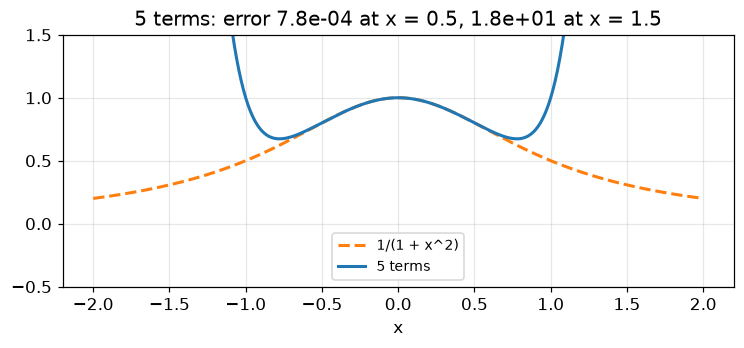

In [5]:
DEFAULT_N_1 = 5
N_RANGE_1 = (1, 30, 1)                      # minimum, maximum, step
GRID_POINTS = 801
X_WINDOW_1 = (-2.0, 2.0)
HEIGHT_1 = (-0.5, 1.5)
SINGLE_FIGURE = (7.0, 3.3)
X_ERRORS_1 = (0.5, 1.5)                     # the two points of the title


def bump(points):
    return 1 / (1 + points ** 2)            # the function 1/(1 + x^2)


def bump_rule(k, a):
    return -a[k - 2]                        # 1 - x^2 + x^4 - ...: minus the coefficient 2 places back


def bump_sum(n, points):
    # the partial sum with n terms: 2 n coefficients, since every other one is 0
    return ol.series_value(ol.series_coefficients(bump_rule, [1.0, 0.0], 2 * n), points)


def terms(n):
    return f"{n} term" + ("" if n == 1 else "s")     # 1 term, 2 terms, ...


def plot_bump(n=DEFAULT_N_1):
    grid = np.linspace(*X_WINDOW_1, GRID_POINTS)
    errors = [abs(float(bump_sum(n, point)) - bump(point)) for point in X_ERRORS_1]
    fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
    ax.plot(grid, bump(grid), "--", color="C1", linewidth=2, label="1/(1 + x^2)")
    ax.plot(grid, bump_sum(n, grid), "-", color="C0", linewidth=2, label=terms(n))
    ax.set_ylim(*HEIGHT_1)
    ax.set_xlabel("x")
    ax.set_title(f"{terms(n)}: error {error_text(errors[0])} at x = {X_ERRORS_1[0]:g}, "
                 f"{error_text(errors[1])} at x = {X_ERRORS_1[1]:g}")
    ax.legend(loc="lower center")
    plt.tight_layout()
    plt.show()


plot_bump()

In [6]:
interact(plot_bump, n=IntSlider(value=DEFAULT_N_1, min=N_RANGE_1[0], max=N_RANGE_1[1], step=N_RANGE_1[2],
                                description="N", continuous_update=False));

interactive(children=(IntSlider(value=5, continuous_update=False, description='N', max=30, min=1), Output()), ...

*The static plot shows*, for $N = 5$ terms, the function (dashed) and the partial sum (solid): they are
close for $x$ between about $-0.7$ and $0.7$; outside they part, and the partial sum shoots up beyond the
picture.

(Answer: at $|x| = 1$. Inside, the partial sums come closer to the function as $N$ grows; outside, they
swing wider and wider as $N$ grows; at $x = \pm1$ they jump between 1 and 0. Why: the series is the
geometric series $1 + u + u^2 + \cdots$ with $u = -x^2$, which needs $|u| < 1$. The function shows the
reason only with complex numbers: $1 + x^2 = 0$ at $x = \pm i$, where the function is infinite, at
distance 1 from 0; Section 4 says why that matters. "Below $10^{-15}$" in the title means below the
computer's rounding.)

In [7]:
# checking code: you can skip reading it; read what it prints
# (the rest of a geometric series: what N terms leave out is (-x^2)^N / (1 + x^2); at N = 30 the error at
# x = 0.5 is 7e-19, below the computer's rounding: the sum then equals the function to the last digit)
ROWS_SHOWN_1 = (1, 5, 10, 20, 30)
print("    N" + "".join(f"   error at x = {point:g}" for point in X_ERRORS_1))
for n in range(N_RANGE_1[0], N_RANGE_1[1] + 1, N_RANGE_1[2]):               # every position of the slider
    errors = [float(bump_sum(n, point)) - bump(point) for point in X_ERRORS_1]
    exact = [-(-point ** 2) ** n / (1 + point ** 2) for point in X_ERRORS_1]
    assert np.allclose(errors, exact, atol=ROUNDING), "slider 1: an error is not as the text says"
    if n in ROWS_SHOWN_1:
        print(f"{n:5d}" + "".join(f"{error_text(abs(error)):>18}" for error in errors))

    N   error at x = 0.5   error at x = 1.5
    1           2.0e-01           6.9e-01
    5           7.8e-04           1.8e+01
   10           7.6e-07           1.0e+03
   20           7.3e-13           3.4e+06
   30       below 1e-15           1.1e+10


## 3. Series at an ordinary point

(Session 27.) **Ordinary and singular points** (Lebl, Section 7.2). For
$P(x)y'' + Q(x)y' + R(x)y = 0$ with polynomials $P$, $Q$, $R$ that have no common factor, the point $x_0$
is **ordinary** when $P(x_0) \ne 0$, and **singular** when $P(x_0) = 0$. At an ordinary point every
solution is a power series in $x - x_0$ (how far it reaches: Section 4).

**The method, on Lebl's Example 7.2.1:** $y'' - y = 0$ near $x_0 = 0$ (here $P = 1$: every point is
ordinary). Its solutions are $\cosh x = \frac{e^x + e^{-x}}{2}$ and $\sinh x = \frac{e^x - e^{-x}}{2}$;
pretend we do not know them.

1. *Try a series:* $y = \sum_{k=0}^{\infty} a_kx^k = a_0 + a_1x + a_2x^2 + \cdots$, with unknown $a_k$.
2. *Differentiate term by term* (Lebl, Section 7.1.4):
   $y' = \sum_{k=1}^{\infty} k\,a_kx^{k-1}$ and $y'' = \sum_{k=2}^{\infty} k(k - 1)\,a_kx^{k-2}$. The
   sums start at 1 and at 2 because $a_0$ and $a_1x$ give 0 after two derivatives.
3. *Shift the index*, so that $y''$ and $y$ both show $x^k$. In $y''$ put $k = j + 2$, so that $j$
   starts at 0, and then call the counter $k$ again:

   $y'' = \sum_{j=0}^{\infty} (j + 2)(j + 1)\,a_{j+2}x^{j}
   = \sum_{k=0}^{\infty} (k + 2)(k + 1)\,a_{k+2}x^{k}$.

   Only the name of the counter has changed, not the terms:

   | | with $k$, from $k = 2$ | with $j = k - 2$, from $j = 0$ |
   |---|---|---|
   | first term | $2 \cdot 1\,a_2x^0$ | $(0 + 2)(0 + 1)\,a_{0+2}x^0$ |
   | second term | $3 \cdot 2\,a_3x^1$ | $(1 + 2)(1 + 1)\,a_{1+2}x^1$ |
   | third term | $4 \cdot 3\,a_4x^2$ | $(2 + 2)(2 + 1)\,a_{2+2}x^2$ |

**The rule of the shift.** To make a sum show $x^k$ where it shows $x^{k+m}$: write $k - m$ in place of
every $k$ inside the sum, and add $m$ to where it starts. In $y''$ above the sum shows $x^{k-2}$, that is
$m = -2$: $k - (-2) = k + 2$ in place of $k$, and the start 2 becomes 0.

4. *Equate coefficients:*
   $y'' - y = \sum_{k=0}^{\infty}\big[(k + 2)(k + 1)\,a_{k+2} - a_k\big]x^k = 0$ for every $x$, and a
   power series that is 0 for every $x$ has every coefficient 0:

$$ a_{k+2} = \frac{a_k}{(k + 2)(k + 1)}, \qquad k = 0, 1, 2, \ldots \qquad\text{(Lebl, (7.2.2), solved
   for } a_{k+2}\text{)} $$

This is a **recurrence relation**. **How to read it:** it gives each coefficient from earlier ones. It does
not give $a_0$ and $a_1$, which stay free: they are $y(0)$ and $y'(0)$. Put $k = 0$:
$a_2 = \frac{a_0}{2 \cdot 1}$. Put $k = 1$: $a_3 = \frac{a_1}{3 \cdot 2}$. Put $k = 2$:
$a_4 = \frac{a_2}{4 \cdot 3} = \frac{a_0}{4 \cdot 3 \cdot 2 \cdot 1}$. With $a_0 = 1$, $a_1 = 0$, by hand:

| $k$ | 0 | 1 | 2 | 3 | 4 | 5 | 6 |
|---|---|---|---|---|---|---|---|
| $a_k$ | 1 | 0 | $\frac12$ | 0 | $\frac{1}{24}$ | 0 | $\frac{1}{720}$ |

that is $1 + \frac{x^2}{2!} + \frac{x^4}{4!} + \frac{x^6}{6!} + \cdots = \cosh x$. With $a_0 = 0$,
$a_1 = 1$ the same rule gives $x + \frac{x^3}{3!} + \frac{x^5}{5!} + \cdots = \sinh x$, and Lebl's general
solution is $y = a_0\cosh x + a_1\sinh x$.

**The computer.** `ol.series_coefficients(rule, initial, n)` gives the first $n$ coefficients. `initial`
is the list of the first ones, here $[a_0, a_1]$; `rule(k, a)` must return $a_k$ from the list `a` of the
earlier ones (`a[k - 2]` is $a_{k-2}$). So the recurrence is written for $a_k$, not for $a_{k+2}$. This is
not a shift of a sum: the rule holds for $k = 0, 1, 2, \ldots$, so it holds with $k - 2$ written in place
of $k$, for $k - 2 = 0, 1, 2, \ldots$, that is for $k = 2, 3, 4, \ldots$:

$$ a_{(k-2)+2} = \frac{a_{k-2}}{\big((k - 2) + 2\big)\big((k - 2) + 1\big)}, \qquad\text{that is}\qquad
   a_k = \frac{a_{k-2}}{k(k - 1)} . $$

In [8]:
def cosh_rule(k, a):
    # Lebl, Example 7.2.1: a_k = a_(k-2) / (k (k - 1)), for k = 2, 3, ...
    return a[k - 2] / (k * (k - 1))


N_COEFFICIENTS = 12                         # a_0 to a_11 (try 20; at least 2, the initial values)
BY_HAND = [1, 0, 1 / 2, 0, 1 / 24, 0, 1 / 720]          # the table above (keep it)
by_computer = ol.series_coefficients(cosh_rule, [1.0, 0.0], N_COEFFICIENTS)
print(" k   by the computer   by hand")
for k, value in enumerate(by_computer):
    print(f"{k:2d} {value:17.10g}" + (f" {BY_HAND[k]:13.10g}" if k < len(BY_HAND) else ""))
shared = min(N_COEFFICIENTS, len(BY_HAND))
assert np.allclose(by_computer[:shared], BY_HAND[:shared]), "the computer disagrees with the table above"
points = np.array([0.5, 1.0, 2.0])
print("partial sum at x =", points, "minus cosh x:", ol.series_value(by_computer, points) - np.cosh(points))

 k   by the computer   by hand
 0                 1             1
 1                 0             0
 2               0.5           0.5
 3                 0             0
 4     0.04166666667 0.04166666667
 5                 0             0
 6    0.001388888889 0.001388888889
 7                 0
 8    2.48015873e-05
 9                 0
10   2.755731922e-07
11                 0
partial sum at x = [0.5 1.  2. ] minus cosh x: [-5.10258502e-13 -2.09919437e-09 -8.74223002e-06]


*The table shows* the computer's coefficients next to the table by hand: the same numbers. With 12
coefficients the partial sum differs from $\cosh x$ by about $5 \cdot 10^{-13}$ at $x = 0.5$ and by about
$10^{-5}$ at $x = 2$: farther from the center, more terms are needed.

(At home.) **Airy's equation** (Lebl, Example 7.2.2; notebook 05E): $y'' - xy = 0$ near $x_0 = 0$. Its
solutions cannot be built from polynomials, exponentials, sines and logarithms. The same four steps; the
new term $xy$ needs the rule of the shift with $m = 1$ ($k - 1$ in place of $k$, the start 0 becomes 1):

$$ xy = x\sum_{k=0}^{\infty} a_kx^k = \sum_{k=0}^{\infty} a_kx^{k+1} = \sum_{k=1}^{\infty} a_{k-1}x^{k}. $$

The $y''$ sum starts at $k = 0$ and the $xy$ sum at $k = 1$: take the $k = 0$ term of $y''$,
$(0 + 2)(0 + 1)\,a_2 = 2a_2$, out of its sum; then both sums start at 1:
$y'' - xy = 2a_2 + \sum_{k=1}^{\infty}\big[(k + 2)(k + 1)\,a_{k+2} - a_{k-1}\big]x^k = 0$. The power $x^0$
gives $2a_2 = 0$, so $a_2 = 0$. The brackets give $a_{k+2} = \dfrac{a_{k-1}}{(k + 2)(k + 1)}$, and with
$k - 2$ in place of $k$: $a_k = \dfrac{a_{k-3}}{k(k - 1)}$ for $k = 3, 4, \ldots$ This rule reaches back
3 places, so the computer needs three initial values, $[a_0, a_1, a_2]$ with $a_2 = 0$. By hand:
$a_3 = \frac{a_0}{6}$, $a_4 = \frac{a_1}{12}$, $a_5 = \frac{a_2}{20} = 0$,
$a_6 = \frac{a_3}{30} = \frac{a_0}{180}$, $a_7 = \frac{a_4}{42} = \frac{a_1}{504}$. Lebl's two solutions
are $y_1 = 1 + \frac{x^3}{6} + \frac{x^6}{180} + \cdots$ (from $a_0 = 1$, $a_1 = 0$) and
$y_2 = x + \frac{x^4}{12} + \frac{x^7}{504} + \cdots$ (from $a_0 = 0$, $a_1 = 1$).

y1: a_3 = 0.1666666667 (1/6 = 0.1666666667), a_6 = 0.0055555556 (1/180 = 0.0055555556)
y2: a_4 = 0.0833333333 (1/12 = 0.0833333333), a_7 = 0.0019841270 (1/504 = 0.0019841270)
     x   Ai by the series      Ai by SciPy           Bi by the series      Bi by SciPy
     1     0.135292416312881     0.135292416312881     1.207423594952871     1.207423594952872
     2     0.034924130423274     0.034924130423274     3.298094999978215     3.298094999978214
    -3    -0.378814293677647    -0.378814293677658    -0.198289626374948    -0.198289626374927


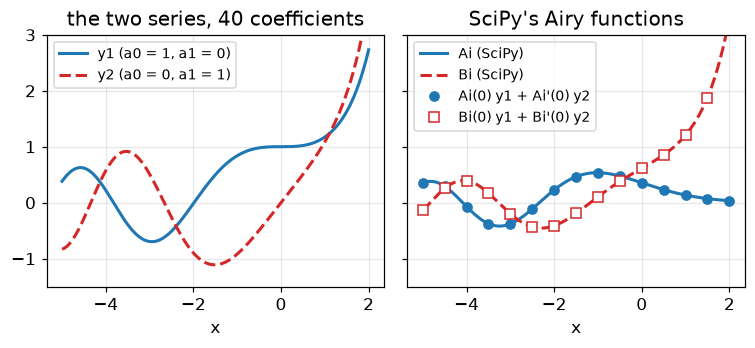

In [9]:
def airy_rule(k, a):
    # Lebl, Example 7.2.2: a_k = a_(k-3) / (k (k - 1)), for k = 3, 4, ...
    return a[k - 3] / (k * (k - 1))


# Against SciPy (optional): y1(0) = 1, y1'(0) = 0, y2(0) = 0, y2'(0) = 1, so the solution with y(0) = a0
# and y'(0) = a1 is a0 y1 + a1 y2; SciPy's Airy functions are two solutions: Ai = Ai(0) y1 + Ai'(0) y2,
# with Ai(0) = 0.3550 and Ai'(0) = -0.2588, and the same for Bi.


AIRY_COEFFICIENTS = 40                      # a_0 to a_39
y1 = ol.series_coefficients(airy_rule, [1.0, 0.0, 0.0], AIRY_COEFFICIENTS)     # a_0 = 1, a_1 = 0, a_2 = 0
y2 = ol.series_coefficients(airy_rule, [0.0, 1.0, 0.0], AIRY_COEFFICIENTS)     # a_0 = 0, a_1 = 1, a_2 = 0
print(f"y1: a_3 = {y1[3]:.10f} (1/6 = {1 / 6:.10f}), a_6 = {y1[6]:.10f} (1/180 = {1 / 180:.10f})")
print(f"y2: a_4 = {y2[4]:.10f} (1/12 = {1 / 12:.10f}), a_7 = {y2[7]:.10f} (1/504 = {1 / 504:.10f})")
ai_0, ai_prime_0, bi_0, bi_prime_0 = airy(0.0)                  # the values at x = 0
AIRY_POINTS = np.array([1.0, 2.0, -3.0])    # the points of the text
AIRY_AGREEMENT = 1e-12
ai_by_series = ai_0 * ol.series_value(y1, AIRY_POINTS) + ai_prime_0 * ol.series_value(y2, AIRY_POINTS)
bi_by_series = bi_0 * ol.series_value(y1, AIRY_POINTS) + bi_prime_0 * ol.series_value(y2, AIRY_POINTS)
ai_by_scipy, _, bi_by_scipy, _ = airy(AIRY_POINTS)
print("     x   Ai by the series      Ai by SciPy           Bi by the series      Bi by SciPy")
for row in zip(AIRY_POINTS, ai_by_series, ai_by_scipy, bi_by_series, bi_by_scipy, strict=True):
    print("{:6g} {:21.15f} {:21.15f} {:21.15f} {:21.15f}".format(*row))
TEXT_AIRY = "the series disagree with SciPy: put back the 40 coefficients and the points 1, 2, -3 of the text"
assert np.allclose(ai_by_series, ai_by_scipy, rtol=0, atol=AIRY_AGREEMENT), TEXT_AIRY
assert np.allclose(bi_by_series, bi_by_scipy, rtol=AIRY_AGREEMENT, atol=0), TEXT_AIRY

# drawing code: you can skip reading it
WIDE_FIGURE = (7.0, 3.3)                    # two panels side by side
X_AIRY = (-5.0, 2.0)
AIRY_HEIGHT = (-1.5, 3.0)
DOTS = 15                                   # points at which the series is drawn as dots
grid = np.linspace(*X_AIRY, GRID_POINTS)
dots = np.linspace(*X_AIRY, DOTS)
ai, _, bi, _ = airy(grid)
fig, (left, right) = plt.subplots(1, 2, figsize=WIDE_FIGURE, sharey=True)
left.plot(grid, ol.series_value(y1, grid), "-", color="C0", linewidth=2, label="y1 (a0 = 1, a1 = 0)")
left.plot(grid, ol.series_value(y2, grid), "--", color="C3", linewidth=2, label="y2 (a0 = 0, a1 = 1)")
left.set_title(f"the two series, {AIRY_COEFFICIENTS} coefficients")
right.plot(grid, ai, "-", color="C0", linewidth=2, label="Ai (SciPy)")
right.plot(grid, bi, "--", color="C3", linewidth=2, label="Bi (SciPy)")
right.plot(dots, ai_0 * ol.series_value(y1, dots) + ai_prime_0 * ol.series_value(y2, dots), "o",
           color="C0", label="Ai(0) y1 + Ai'(0) y2")
right.plot(dots, bi_0 * ol.series_value(y1, dots) + bi_prime_0 * ol.series_value(y2, dots), "s",
           color="C3", markerfacecolor="white", label="Bi(0) y1 + Bi'(0) y2")
right.set_title("SciPy's Airy functions")
for ax in (left, right):
    ax.set_ylim(*AIRY_HEIGHT)
    ax.set_xlabel("x")
    ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

*The plot shows*, left, the two series solutions $y_1$ and $y_2$; right, SciPy's $\mathrm{Ai}$ and
$\mathrm{Bi}$ (lines) and the combinations of the series (dots), on them. As Lebl says, they oscillate for
negative $x$, like solutions of $y'' + y = 0$, and grow for positive $x$, like those of $y'' - y = 0$
($\mathrm{Ai}$, up to a factor, is the one that decays).

## 4. How far a series solution reaches (the theory exercise)

(Session 27.) **The fact** (a consequence of Boyce and DiPrima, Theorem 5.3.1; the step is written after
the answers, Section 9). Let $x_0$ be an ordinary point of $P(x)y'' + Q(x)y' + R(x)y = 0$, with
polynomials $P$, $Q$, $R$. Then every series solution at $x_0$ converges at least for $|x - x_0| < d$,
where $d$ is the distance from $x_0$ to the nearest zero of $P$, **complex zeros included**. How to use it:
1. Find the zeros of $P(x)$, complex ones too (`np.roots` does it for a polynomial).
2. A complex number $z = a + bi$ is the point $(a, b)$ of the plane, and $x_0$ is the point $(x_0, 0)$,
   so the distance is $|z - x_0| = \sqrt{(a - x_0)^2 + b^2}$.
3. The smallest of these distances is a lower bound for the radius: "at least" (it may reach farther).

**Why complex points matter.** The partial sums are polynomials, which can be computed at a complex $x$
too. A power series in fact converges for every complex $x$ with $|x - x_0| < \rho$: inside a disk of
the complex plane, whose trace on the real line is the interval $x_0 - \rho < x < x_0 + \rho$. The disk
cannot contain a point where the solution or one of its derivatives blows up (inside the disk the series
and every derivative add up to finite numbers), and a zero of $P$ can be such a point. So the real
interval **may** be cut at the distance $d$ although nothing happens on the real line; it is not always
cut there. The equation below has the solution $y = 1$ too (with $y(0) = 1$, $y'(0) = 0$): a series that
stops, and works for every $x$. This is why the rule says "at least".

**The notebook's example:** $(1 + x^2)y'' + 2xy' = 0$, $y(0) = 0$, $y'(0) = 1$, solved by
$y = \arctan x$ (then $(1 + x^2)y' = 1$; differentiate). $\arctan x$ is smooth on the real line, but
$P = 1 + x^2$ has the zeros $\pm i$, at distance 1 from $x_0 = 0$ (where $\arctan$ blows up): the series
converges at least for $|x| < 1$.

zeros of P: [0.+1.j 0.-1.j] ; distances from x0: [1. 1.] ; the bound: 1.0


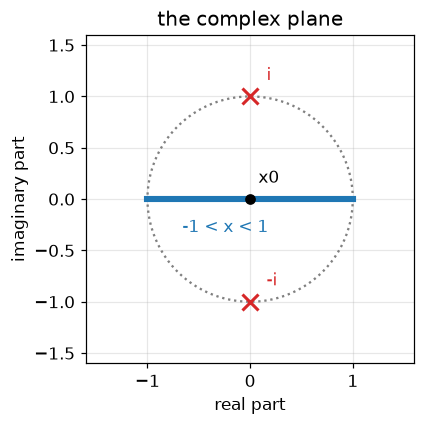

In [10]:
P_COEFFICIENTS = [1, 0, 1]                  # P(x) = 1 x^2 + 0 x + 1 (try [1, 0, 4], or [1, -2, 5])
X0 = 0.0                                    # the center of the series (try 0.5)
zeros = np.roots(P_COEFFICIENTS) + 0.0      # (+ 0.0 writes 0 for -0)
if zeros.size == 0:
    print("P has no zeros (a constant P): every point is ordinary, and the series solutions converge for "
          "every x; give P of degree 1 or more to see a circle")
else:
    distances = np.abs(zeros - X0)
    bound = distances.min()
    print("zeros of P:", zeros, "; distances from x0:", distances, "; the bound:", bound)

# drawing code: you can skip reading it
SQUARE_FIGURE = (4.0, 4.0)
PLANE_MARGIN = 0.6                          # room around the circle and the zeros
CIRCLE_POINTS = 200
LABEL_SHARE = 0.1                           # how far a label sits from its point, as a part of the window


def draw_plane():
    # the circle of the rule, the zeros of P and the interval of the real line
    reach = max(abs(X0) + bound, np.abs(zeros).max()) + PLANE_MARGIN
    shift = LABEL_SHARE * reach
    angles = np.linspace(0.0, 2 * np.pi, CIRCLE_POINTS)
    fig, ax = plt.subplots(figsize=SQUARE_FIGURE)
    ax.plot(X0 + bound * np.cos(angles), bound * np.sin(angles), ":", color="gray")
    ax.plot(zeros.real, zeros.imag, "x", color="C3", markersize=10, markeredgewidth=2)
    for zero in zeros:
        # the label as on paper: i, -i, 1+2i, 3 (no "0+1i")
        size = "" if abs(zero.imag) == 1 else f"{abs(zero.imag):g}"
        imaginary = "" if zero.imag == 0 else ("+" if zero.imag > 0 else "-") + size + "i"
        real = f"{zero.real:g}" if zero.real or not imaginary else ""
        ax.annotate((real + imaginary).lstrip("+"), (zero.real, zero.imag),
                    xytext=(zero.real + shift, zero.imag + shift), color="C3")
    ax.plot([X0 - bound, X0 + bound], [0.0, 0.0], "-", color="C0", linewidth=4)
    ax.annotate(f"{X0 - bound:.3g} < x < {X0 + bound:.3g}", (X0, 0.0),
                xytext=(X0 - bound / 2 - shift, -2 * shift), color="C0")
    ax.plot(X0, 0.0, "o", color="black")
    ax.annotate("x0", (X0, 0.0), xytext=(X0 + shift / 2, shift))
    ax.set_xlim(-reach, reach)
    ax.set_ylim(-reach, reach)
    ax.set_aspect("equal")
    ax.set_xlabel("real part")
    ax.set_ylabel("imaginary part")
    ax.set_title("the complex plane")
    plt.tight_layout()
    plt.show()


if zeros.size:
    draw_plane()

*The plot shows* the complex plane: the zeros $\pm i$ of $P$ (crosses), the circle of radius 1 around
$x_0 = 0$ that passes through them, and the interval $-1 < x < 1$ of the real line inside it. (With other
numbers in the first two lines of the cell, the circle and the interval follow them.)

(At home.) **The series of the example.** With the series of $y'$ and $y''$ of Section 3:
* $x^2y'' = \sum_{k=0}^{\infty} k(k - 1)\,a_kx^k$: $x^2$ times $x^{k-2}$ is $x^k$, so no shift is needed
  (and the sum may start at 0, since $k(k - 1) = 0$ for $k = 0$ and $1$);
* $2xy' = \sum_{k=0}^{\infty} 2k\,a_kx^k$, in the same way;
* $y'' = \sum_{k=0}^{\infty}(k + 2)(k + 1)\,a_{k+2}x^k$, shifted in Section 3.

The coefficient of $x^k$ is $(k + 2)(k + 1)\,a_{k+2} + k(k - 1)\,a_k + 2k\,a_k$, and it must be 0. Since
$k(k - 1) + 2k = k(k + 1)$,

$$ a_{k+2} = -\frac{k(k + 1)}{(k + 2)(k + 1)}\,a_k = -\frac{k}{k + 2}\,a_k, \qquad\text{for the computer}
   \qquad a_k = -\frac{k - 2}{k}\,a_{k-2}. $$

With $a_0 = 0$, $a_1 = 1$: $a_3 = -\frac13$, $a_5 = -\frac35 \cdot \big(-\frac13\big) = \frac15$,
$a_7 = -\frac57 \cdot \frac15 = -\frac17$. The series is $x - \frac{x^3}{3} + \frac{x^5}{5} - \frac{x^7}{7}
+ \cdots$, the series of $\arctan x$.

a_0 to a_7: [ 0.          1.          0.         -0.33333333  0.          0.2
  0.         -0.14285714]
the ratio test of Section 2: |a_(k+2) / a_k| = k / (k + 2) for k = 1, 11, 101: [0.333, 0.846, 0.981]


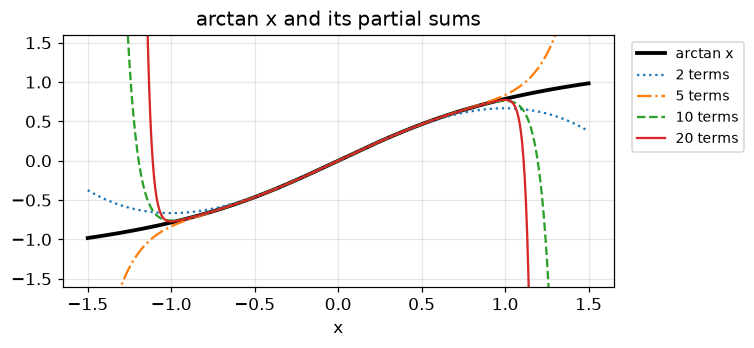

In [11]:
def arctan_rule(k, a):
    # (1 + x^2) y'' + 2x y' = 0: a_k = -(k - 2) / k a_(k-2)
    return -(k - 2) / k * a[k - 2]


TERMS_SHOWN = (2, 5, 10, 20)                # numbers of terms in the figure
SHOWN_ARCTAN = 8                            # coefficients printed
arctan_coefficients = ol.series_coefficients(arctan_rule, [0.0, 1.0], 2 * max(TERMS_SHOWN))
print(f"a_0 to a_{SHOWN_ARCTAN - 1}:", arctan_coefficients[:SHOWN_ARCTAN] + 0.0)    # (+ 0.0: no -0.)
assert np.allclose(arctan_coefficients[:SHOWN_ARCTAN], [0, 1, 0, -1 / 3, 0, 1 / 5, 0, -1 / 7]), \
    "not the numbers of the text"
assert sp.series(sp.atan(x), x, 0, SHOWN_ARCTAN).removeO() == x - x ** 3 / 3 + x ** 5 / 5 - x ** 7 / 7
RATIO_K = (1, 11, 101)
known = [k for k in RATIO_K if k + 2 < len(arctan_coefficients)]       # the k whose a_(k+2) is computed
ratios = [abs(arctan_coefficients[k + 2] / arctan_coefficients[k]) for k in known]
assert np.allclose(ratios, [k / (k + 2) for k in known]), "the ratio is not k / (k + 2)"
print("the ratio test of Section 2: |a_(k+2) / a_k| = k / (k + 2) for k = 1, 11, 101:",
      [round(k / (k + 2), 3) for k in RATIO_K])

# drawing code: you can skip reading it
X_ARCTAN = (-1.5, 1.5)
ARCTAN_HEIGHT = (-1.6, 1.6)
grid = np.linspace(*X_ARCTAN, GRID_POINTS)
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
ax.plot(grid, np.arctan(grid), "-", color="black", linewidth=2.5, label="arctan x")
for n, style in zip(TERMS_SHOWN, (":", "-.", "--", "-"), strict=True):
    ax.plot(grid, ol.series_value(arctan_coefficients[:2 * n], grid), style, linewidth=1.5, label=terms(n))
ax.set_ylim(*ARCTAN_HEIGHT)
ax.set_xlabel("x")
ax.set_title("arctan x and its partial sums")
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
plt.tight_layout()
plt.show()

*The plot shows* $\arctan x$ and its partial sums with 2, 5, 10 and 20 terms: they gather on the curve
between $-1$ and $1$, and leave it outside, the more steeply the more terms. The ratio test of Section 2
agrees: $\left|\dfrac{a_{k+2}x^{k+2}}{a_kx^k}\right| = \dfrac{k}{k + 2}\,x^2 \to x^2$, so the radius is
exactly 1, the bound of the rule.

## 5. Singular points and the method of Frobenius

(Session 28.) *In class:* why $x^r$, regular singular points, the Euler equation, the indicial equation
and the table of cases; in Section 6, Bessel's equation, the series of $J_0$ and slider 2. *At home:* the
cells marked "(At home.)" and the answers (Section 9).

The **method of Frobenius** puts a power $x^r$ in front of a series. Why (Lebl, Example 7.3.1):
$2xy' - y = 0$ has a singular point at $x = 0$ (a first-order equation, but the idea is the same). Try
a series: $2xy' = \sum 2k\,a_kx^k$, so the coefficient of $x^k$ is $(2k - 1)\,a_k = 0$,
and every $a_k$ is 0: only $y = 0$. Now try $y = x^r$:
$2x \cdot rx^{r-1} - x^r = (2r - 1)\,x^r = 0$, so $r = \frac12$ and $y = Cx^{1/2}$, for $x > 0$.

**Why $x^r$ in front.** A power series has only the powers $0, 1, 2, \ldots$, and its slope at 0 is the
number $a_1$. The solution $x^{1/2}$ has a slope $\frac{1}{2\sqrt{x}}$ that grows without bound near 0:

| $x$ | 1 | 0.01 | 0.0001 |
|---|---|---|---|
| $\sqrt{x}$ | 1 | 0.1 | 0.01 |
| slope $\frac{1}{2\sqrt x}$ | 0.5 | 5 | 50 |

No power series behaves so; $y = x^r(a_0 + a_1x + \cdots)$ with $a_0 \ne 0$ can (were $a_0 = 0$, one
more $x$ could be taken out, and $r$ would be 1 larger). Such solutions are for $x > 0$; $r$ may be
negative or complex.

**Regular singular points** (Lebl, Section 7.3.2). A singular point $x_0 = 0$ is **regular** when the two
limits

$$ p_0 = \lim_{x \to 0} x\,\frac{Q(x)}{P(x)}, \qquad q_0 = \lim_{x \to 0} x^2\,\frac{R(x)}{P(x)} $$

exist and are finite (why these two: the indicial equation below). Lebl's Example 7.3.3:
$x^2y'' + x(1 + x)y' + (\pi + x^2)y = 0$ has $p_0 = \lim \frac{x \cdot x(1 + x)}{x^2} = \lim (1 + x) = 1$
and $q_0 = \lim \frac{x^2(\pi + x^2)}{x^2} = \pi$: regular. His "slight change"
$x^2y'' + (1 + x)y' + (\pi + x^2)y = 0$ has $x\,\frac{Q}{P} = \frac{1 + x}{x}$, with no limit at 0:
singular, but not regular. SymPy computes the limits:

In [12]:
example_733 = (x ** 2, x * (1 + x), sp.pi + x ** 2)         # P, Q, R of Lebl's Example 7.3.3
changed = (x ** 2, 1 + x, sp.pi + x ** 2)                   # his slight change
for name, (big_p, big_q, big_r) in (("Example 7.3.3", example_733), ("the slight change", changed)):
    p0 = sp.limit(x * big_q / big_p, x, 0, "+")             # the limit as x -> 0 from the right
    q0 = sp.limit(x ** 2 * big_r / big_p, x, 0, "+")
    print(f"{name}: p0 = {p0}, q0 = {q0}")

Example 7.3.3: p0 = 1, q0 = pi
the slight change: p0 = oo, q0 = pi


(`oo` is SymPy's infinity: no finite limit.)

**The Euler equation** (not Euler's method of notebook 04, nor Euler's formula of notebook 06), the
simplest case: $x^2y'' + p_0\,xy' + q_0\,y = 0$ with constants $p_0$, $q_0$, which are also its two
limits. Try $y = x^r$: $y' = rx^{r-1}$ and $y'' = r(r - 1)x^{r-2}$, so $x^2y'' = r(r - 1)x^r$ and
$p_0\,xy' = p_0\,rx^r$:

$$ x^2y'' + p_0\,xy' + q_0\,y = \big[r(r - 1) + p_0\,r + q_0\big]\,x^r = 0 \quad\Longrightarrow\quad
   r(r - 1) + p_0\,r + q_0 = 0, $$

a quadratic, like the characteristic equation of notebook 06. Lebl's Exercise 7.3.8: $x^2y'' - y = 0$
($p_0 = 0$, $q_0 = -1$) gives $r(r - 1) - 1 = 0$, $r = \frac{1 \pm \sqrt5}{2}$, and
$y = Ax^{(1 + \sqrt5)/2} + Bx^{(1 - \sqrt5)/2}$ (his answer).

**The indicial equation: the lowest power must vanish.** Divide $Py'' + Qy' + Ry = 0$ by $P$ and
multiply by $x^2$:

$$ x^2y'' + x\Big(x\frac{Q}{P}\Big)y' + \Big(x^2\frac{R}{P}\Big)y = 0 . $$

Near a regular singular point $x\frac{Q}{P}$ and $x^2\frac{R}{P}$ are power series, $p_0 + p_1x + \cdots$
and $q_0 + q_1x + \cdots$ (their limits at 0 are finite), so this is an Euler equation plus terms with at
least one more power of $x$. Put $y = x^r(a_0 + a_1x + \cdots)$ in it. The lowest power that appears is
$x^r$, and only $a_0$ with $p_0$ and $q_0$ contributes to it (every $p_1x$, $q_1x$, ... raises the
power): its coefficient is $a_0\big[r(r - 1) + p_0r + q_0\big]$. It must vanish, and $a_0 \ne 0$, so

$$ r(r - 1) + p_0\,r + q_0 = 0 \qquad\text{(the indicial equation).} $$

`ol.indicial_roots(p0, q0)` returns its two roots and their case, one of four names; the cell prints the
names, and the roots of four equations, one for each case.

In [13]:
for name in CASE_NAMES:
    print(f"ol.{name:20s} = {getattr(ol, name)!r}")
print()
EXAMPLES = {                                # (p0, q0) of four equations, one for each case
    "x^2 y'' - y = 0 (Lebl, Exercise 7.3.8)": (0.0, -1.0),
    "Lebl, Example 7.3.2": (0.0, 1 / 4),
    "x^2 y'' - 2y = 0": (0.0, -2.0),
    "Lebl, Example 7.3.3": (1.0, np.pi),
}
for name, (p0, q0) in EXAMPLES.items():
    r1, r2, case = ol.indicial_roots(p0, q0)
    print(f"{name}: r1 = {r1:.4f}, r2 = {r2:.4f}: {case}")

MY_P0, MY_Q0 = 3.0, 1.0                     # your own p0 and q0: try others
print("yours:", ol.indicial_roots(MY_P0, MY_Q0))

ol.INDICIAL_NOT_INTEGER = 'two real roots, difference not a whole number'
ol.INDICIAL_DOUBLE      = 'double root'
ol.INDICIAL_INTEGER     = 'two real roots, difference a whole number'
ol.INDICIAL_COMPLEX     = 'complex roots'

x^2 y'' - y = 0 (Lebl, Exercise 7.3.8): r1 = 1.6180, r2 = -0.6180: two real roots, difference not a whole number
Lebl, Example 7.3.2: r1 = 0.5000, r2 = 0.5000: double root
x^2 y'' - 2y = 0: r1 = 2.0000, r2 = -1.0000: two real roots, difference a whole number
Lebl, Example 7.3.3: r1 = 0.0000+1.7725j, r2 = 0.0000-1.7725j: complex roots
yours: (-1.0, -1.0, 'double root')


When the roots are real, one solution is always $y_1 = x^{r_1}(a_0 + a_1x + \cdots)$ with the larger root
$r_1$ (Boyce and DiPrima, Theorem 5.6.1); when they are complex, either root gives a complex solution
$y_1$ (last row). The case decides a second solution, for $x > 0$ (Lebl, Section 7.3.2, items iii to vi of
the list after Theorem 7.3.1), as the three cases of notebook 06 did:

| name in odelib | the roots | Lebl | example | a second solution |
|---|---|---|---|---|
| `ol.INDICIAL_NOT_INTEGER` | real, unequal, not 1, 2, ... apart | iii | $x^2y''=y$ | $x^{r_2}(b_0+\cdots)$ |
| `ol.INDICIAL_DOUBLE` | real and equal | iv | Example 7.3.2 | $x^{r_1}(b_0 + \cdots) + (\ln x)\,y_1$ |
| `ol.INDICIAL_INTEGER` | real, 1, 2, ... apart | v | $x^2y''-2y=0$ | $x^{r_2}(b_0 + \cdots) + C(\ln x)y_1$ |
| `ol.INDICIAL_COMPLEX` | $\alpha \pm i\beta$ | vi | Example 7.3.3 | the imaginary part of $y_1$ |

In row v, $C$ may be 0; in row vi the real part of $y_1$ is the other solution. The $\ln x$ plays the
part of the $t$ in the $te^{rt}$ of notebook 06, and so it does for complex roots: for $r = \alpha + i\beta$,
$x^r = x^\alpha x^{i\beta} = x^\alpha e^{i\beta\ln x}
= x^\alpha\big(\cos(\beta\ln x) + i\sin(\beta\ln x)\big)$,
by Euler's formula, with $\ln x$ in the place of $t$ in $e^{\alpha t}(\cos\beta t + i\sin\beta t)$.

(At home.) **Lebl's Example 7.3.2, with the computer.** $4x^2y'' - 4x^2y' + (1 - 2x)y = 0$:
$p_0 = \lim x\frac{-4x^2}{4x^2} = 0$ and $q_0 = \lim x^2\frac{1 - 2x}{4x^2} = \frac14$, so
$r(r - 1) + \frac14 = \big(r - \frac12\big)^2 = 0$: the double root $r = \frac12$ (printed above). With
$y = \sum a_kx^{k+r}$, $y' = \sum (k + r)\,a_kx^{k+r-1}$ and $y'' = \sum (k + r)(k + r - 1)\,a_kx^{k+r-2}$,
the four terms of the equation are

| term | as a series | coefficient of $x^{k+r}$ |
|---|---|---|
| $4x^2y''$ | $\sum 4(k + r)(k + r - 1)\,a_kx^{k+r}$ | $4(k + r)(k + r - 1)\,a_k$ |
| $-4x^2y'$ | $\sum -4(k + r)\,a_kx^{k+r+1}$ | $-4(k - 1 + r)\,a_{k-1}$ (shift rule, $m = 1$; $r$ stays) |
| $y$ | $\sum a_kx^{k+r}$ | $a_k$ |
| $-2xy$ | $\sum -2a_kx^{k+r+1}$ | $-2a_{k-1}$ (shift rule, $m = 1$; $r$ stays) |

For $k = 0$ only the first and third rows count: $\big[4r(r - 1) + 1\big]a_0 = 0$, the indicial equation
times 4. For $k \ge 1$ (Lebl):

$$ a_k = \frac{4(k + r - 1) + 2}{4(k + r)(k + r - 1) + 1}\,a_{k-1}. $$

The exponent $r$ is a number inside the rule. By hand with $r = \frac12$, the fraction is
$\frac{4k}{4k^2} = \frac1k$: $a_1 = a_0$, $a_2 = \frac{a_1}{2}$, $a_3 = \frac{a_2}{3}$, so
$a_k = \frac{1}{k!}$ for $a_0 = 1$, and $y_1 = x^{1/2}e^x$ ("That was lucky!", Lebl).

In [14]:
EXPONENT_732 = ol.indicial_roots(0.0, 1 / 4)[0]     # the exponent r of Example 7.3.2: the double root 1/2


def rule_732(k, a):
    # Lebl, Example 7.3.2: a_k = (4 (k + r - 1) + 2) / (4 (k + r)(k + r - 1) + 1) a_(k-1), with r inside
    r = EXPONENT_732
    return (4 * (k + r - 1) + 2) / (4 * (k + r) * (k + r - 1) + 1) * a[k - 1]


COEFFICIENTS_732 = 20                       # coefficients computed
SHOWN_732 = 6                               # coefficients printed
coefficients_732 = ol.series_coefficients(rule_732, [1.0], COEFFICIENTS_732)
print(f"a_0 to a_{SHOWN_732 - 1}:", coefficients_732[:SHOWN_732])
print("1/k!      :", np.array([1 / factorial(k) for k in range(SHOWN_732)]))
points = np.array([0.25, 1.0, 2.0])
print("at x =", points)
print("x^r times the partial sum:", points ** EXPONENT_732 * ol.series_value(coefficients_732, points))
print("x^(1/2) e^x              :", np.sqrt(points) * np.exp(points))

a_0 to a_5: [1.         1.         0.5        0.16666667 0.04166667 0.00833333]
1/k!      : [1.         1.         0.5        0.16666667 0.04166667 0.00833333]
at x = [0.25 1.   2.  ]
x^r times the partial sum: [ 0.64201271  2.71828183 10.44970335]
x^(1/2) e^x              : [ 0.64201271  2.71828183 10.44970335]


## 6. Bessel functions

(Session 28.) **Bessel's equation of order $\nu$** (Lebl, Section 7.3.3, where the order is called $p$;
vibrating drums, heat in cylinders): $x^2y'' + xy' + (x^2 - \nu^2)\,y = 0$, where $\nu$ is a number given
with the equation. Here $P = x^2$, $Q = x$, $R = x^2 - \nu^2$, so $p_0 = 1$ for every order and
$q_0 = -\nu^2$; the indicial equation is $r(r - 1) + r - \nu^2 = r^2 - \nu^2 = 0$: $r = \pm\nu$ (Lebl).

**Order 0, the series of $J_0$.** For $\nu = 0$ the root is $r = 0$ (twice): an ordinary power series
$y = \sum a_kx^k$. The three terms:
* $x^2y'' = \sum k(k - 1)\,a_kx^k$ and $xy' = \sum k\,a_kx^k$ (no shift);
* $x^2y = \sum a_kx^{k+2} = \sum_{k=2}^{\infty} a_{k-2}x^k$ (the rule of the shift, $m = 2$).

The power $x^1$: $(0 + 1)\,a_1 = 0$, so $a_1 = 0$. The power $x^k$, $k \ge 2$:
$\big[k(k - 1) + k\big]a_k + a_{k-2} = k^2a_k + a_{k-2} = 0$, so

$$ a_k = -\frac{a_{k-2}}{k^2}. $$

With $a_0 = 1$: $a_2 = -\frac14$, $a_4 = -\frac{a_2}{16} = \frac{1}{64}$,
$a_6 = -\frac{a_4}{36} = -\frac{1}{2304}$. This is $J_0(x) = 1 - \frac{x^2}{4} + \frac{x^4}{64} -
\frac{x^6}{2304} + \cdots$, Lebl's $J_n$ for $n = 0$, which SciPy calls `jv(0, x)`.

In [15]:
def bessel_0_rule(k, a):
    # Bessel's equation of order 0, r = 0: a_k = -a_(k-2) / k^2
    return -a[k - 2] / k ** 2


J0_TERMS = 15                               # terms that are not 0: 2 J0_TERMS coefficients
SHOWN_J0 = 7                                # coefficients printed
j0_coefficients = ol.series_coefficients(bessel_0_rule, [1.0, 0.0], 2 * J0_TERMS)
with np.printoptions(suppress=True):        # decimals, not powers of 10
    print(f"a_0 to a_{SHOWN_J0 - 1}:", j0_coefficients[:SHOWN_J0] + 0.0)
print("1/64 =", 1 / 64, "and 1/2304 =", 1 / 2304)
J0_POINTS = np.array([1.0, jn_zeros(0, 1)[0], 4.0])         # the second one is the first zero of J_0
J0_AGREEMENT = 1e-12
by_series = ol.series_value(j0_coefficients, J0_POINTS)
print("x       :", J0_POINTS)
SHOWN_DIGITS = 12                           # (a value 1e-16 at the zero prints as 0)
print("series  :", np.round(by_series, SHOWN_DIGITS) + 0.0)
print("jv(0, x):", np.round(jv(0, J0_POINTS), SHOWN_DIGITS) + 0.0)
assert np.allclose(by_series, jv(0, J0_POINTS), rtol=0, atol=J0_AGREEMENT), "the series disagrees with SciPy"

a_0 to a_6: [ 1.          0.         -0.25        0.          0.015625    0.
 -0.00043403]
1/64 = 0.015625 and 1/2304 = 0.00043402777777777775
x       : [1.         2.40482556 4.        ]
series  : [ 0.76519769  0.         -0.39714981]
jv(0, x): [ 0.76519769  0.         -0.39714981]


**Slider 2: how many terms?** By the ratio test of Section 2,
$\left|\dfrac{a_kx^k}{a_{k-2}x^{k-2}}\right| = \dfrac{x^2}{k^2} \to 0$ for every $x$: the radius is
infinite. The slider sets the number $N$ of terms; the plot shows the partial sum and SciPy's $J_0$, and
the title its value at $x = 10$ and its largest error on $0 \le x \le 10$. Before moving it: how many
terms are needed for $J_0$ to be right to 8 decimals for every $x$ up to 10 (an error below $10^{-8}$)?

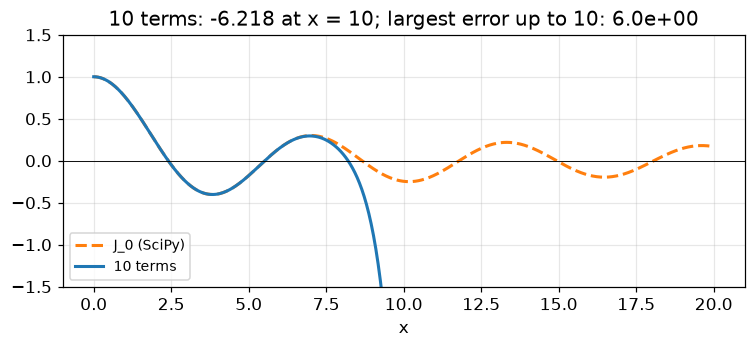

In [16]:
DEFAULT_N_2 = 10
N_RANGE_2 = (1, 30, 1)                      # minimum, maximum, step
X_WINDOW_2 = (0.0, 20.0)
HEIGHT_2 = (-1.5, 1.5)
X_FAR = 10.0                                # where the title reads the partial sum
all_j0 = ol.series_coefficients(bessel_0_rule, [1.0, 0.0], 2 * N_RANGE_2[1])


def j0_sum(n, points):
    return ol.series_value(all_j0[:2 * n], points)          # n terms that are not 0


def j0_error(n):
    # the largest error of n terms on 0 <= x <= X_FAR
    grid = np.linspace(0.0, X_FAR, GRID_POINTS)
    return float(np.max(np.abs(j0_sum(n, grid) - jv(0, grid))))


def plot_bessel(n=DEFAULT_N_2):
    grid = np.linspace(*X_WINDOW_2, GRID_POINTS)
    fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
    ax.plot(grid, jv(0, grid), "--", color="C1", linewidth=2, label="J_0 (SciPy)")
    ax.plot(grid, j0_sum(n, grid), "-", color="C0", linewidth=2, label=terms(n))
    ax.axhline(0.0, color="black", linewidth=0.6)
    ax.set_ylim(*HEIGHT_2)
    ax.set_xlabel("x")
    ax.set_title(f"{terms(n)}: {float(j0_sum(n, X_FAR)):.4g} at x = {X_FAR:g}; "
                 f"largest error up to {X_FAR:g}: {error_text(j0_error(n))}")
    ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


plot_bessel()

In [17]:
interact(plot_bessel, n=IntSlider(value=DEFAULT_N_2, min=N_RANGE_2[0], max=N_RANGE_2[1], step=N_RANGE_2[2],
                                  description="N", continuous_update=False));

interactive(children=(IntSlider(value=10, continuous_update=False, description='N', max=30, min=1), Output()),...

*The static plot shows*, for $N = 10$ terms, SciPy's $J_0$ (dashed) and the partial sum (solid): they agree
up to about $x = 7$; then the partial sum leaves the picture, and at $x = 10$ it is $-6.218$ instead of
$J_0(10) = -0.2459$.

(Answer: by eye, about 15 terms (error $5 \cdot 10^{-4}$, too small to see); to 8 decimals, 20: with 19
the largest error up to $x = 10$ is $2 \cdot 10^{-8}$, with 20 it is $1.5 \cdot 10^{-9}$. An infinite
radius says that the partial sums settle in the end, not that few terms are enough: at $x = 10$ the terms
grow to about 700 before they shrink, and they cancel. (Farther out: Section 9.)

In [18]:
# checking code: you can skip reading it; read what it prints
J0_TARGET = 1e-8                            # "right to 8 decimals up to x = 10": every error below this
J0_ENOUGH, J0_TOO_FEW = 20, 19              # the answer: 20 terms are enough, 19 are not
TEXT_TERMS, TEXT_VALUE, TEXT_DIGITS = 10, -6.2176, 1e-4     # 10 terms give -6.2176 at x = 10 (the text)
ROWS_SHOWN_2 = (5, 10, 15, 19, 20, 25, 30)
TEXT_J0 = ("this cell checks the numbers of the answer: put back X_FAR and N_RANGE_2 as they were "
           "(10.0; 1 to 30)")
print("    N   value at x = 10   largest error on 0 <= x <= 10")
for n in ROWS_SHOWN_2:
    print(f"{n:5d} {float(j0_sum(n, X_FAR)):17.6f} {error_text(j0_error(n)):>21}")
assert j0_error(J0_ENOUGH) < J0_TARGET < j0_error(J0_TOO_FEW), TEXT_J0
assert abs(float(j0_sum(TEXT_TERMS, X_FAR)) - TEXT_VALUE) < TEXT_DIGITS, TEXT_J0
print("J_0(10) by SciPy:", jv(0, X_FAR))

    N   value at x = 10   largest error on 0 <= x <= 10
    5        376.390625               3.8e+02
   10         -6.217617               6.0e+00
   15         -0.245440               5.0e-04
   19         -0.245936               2.3e-08
   20         -0.245936               1.5e-09
   25         -0.245936               7.9e-14
   30         -0.245936               7.9e-14
J_0(10) by SciPy: -0.24593576445134832


(Optional; at home.) **Other equations lead to Bessel's** (Lebl, Example 7.3.4). In
$xy'' + y' + \lambda^2xy = 0$ ($\lambda > 0$) put $t = \lambda x$ (a new variable, not time):
$xy' = t\frac{dy}{dt}$, $x^2y'' = t^2\frac{d^2y}{dt^2}$, $\lambda^2x^2 = t^2$, and the equation times $x$
is Bessel's of order 0 in $t$: $y = AJ_0(\lambda x) + BY_0(\lambda x)$. $Y_0$, SciPy's `yv(0, x)`, is a
second solution for the double root $r = 0$, with a $\ln x$ in it (row iv of the table); it goes to
$-\infty$ at $x = 0$ (Lebl).

x y'' + y' + lambda^2 x y with y = J_0(lambda x): 0
x      : [1.e+00 1.e-01 1.e-03 1.e-06]
Y_0(x) : [ 0.08825696 -1.53423865 -4.47141661 -8.86903148]


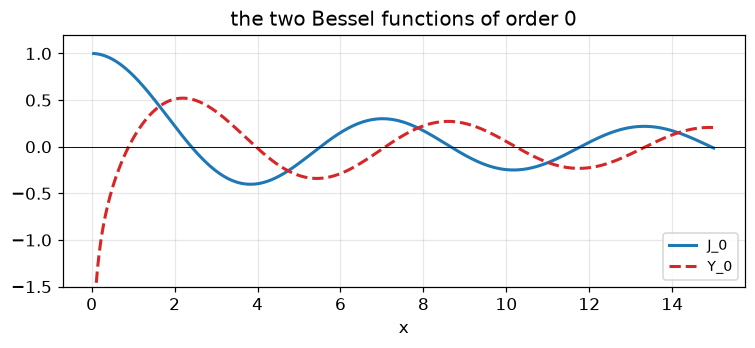

In [19]:
lam = sp.symbols("lambda", positive=True)
y_734 = sp.besselj(0, lam * x)              # SymPy's J_0(lambda x)
residual = sp.simplify(x * y_734.diff(x, 2) + y_734.diff(x) + lam ** 2 * x * y_734)
print("x y'' + y' + lambda^2 x y with y = J_0(lambda x):", residual)
Y_POINTS = np.array([1.0, 0.1, 0.001, 1e-6])
print("x      :", Y_POINTS)
print("Y_0(x) :", yv(0, Y_POINTS))

# drawing code: you can skip reading it
X_BESSEL = (0.05, 15.0)
BESSEL_HEIGHT = (-1.5, 1.2)
grid = np.linspace(*X_BESSEL, GRID_POINTS)
fig, ax = plt.subplots(figsize=SINGLE_FIGURE)
ax.plot(grid, jv(0, grid), "-", color="C0", linewidth=2, label="J_0")
ax.plot(grid, yv(0, grid), "--", color="C3", linewidth=2, label="Y_0")
ax.axhline(0.0, color="black", linewidth=0.6)
ax.set_ylim(*BESSEL_HEIGHT)
ax.set_xlabel("x")
ax.set_title("the two Bessel functions of order 0")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

*The plot shows* $J_0$ (solid), from 1, and $Y_0$ (dashed), from $-\infty$; both oscillate and slowly
shrink, but they are not periodic.

## 7. Where to go next

Next: notebook 22, numerical methods, part 2. Left out (Lebl, Sections 7.2 and 7.3): the second
solutions with $\ln x$ in full, Bessel functions of other orders, right-hand sides. Not in Lebl: series
about the point at infinity.

## 8. Exercises

Final answers are at the end; try first. After Session 27: Exercises 1(a)-(b), 2(a)-(b), 3(i)-(ii) and
4; after Session 28: the rest. Lebl's exercise numbers are those of the list at the end of his Chapter 7.

**Before you start:** run the whole notebook (the `>>` button at the top, then *Confirm Kernel Restart*; or the menu *Run > Run All Cells*), every time you open it: the exercises use what the
cells above define. In an answer cell change only the lines above the line that starts with `# ----`, then press Shift+Enter. If Python does not accept what you type, see "How to type
mathematics" in notebook 00, or click `+` at the top, type `ol.guide("typing")` in the new cell and press Shift+Enter.

### Exercise 1 - Predict (no computer)

* (a) The radius of convergence of the series of $\dfrac{1}{4 + x^2}$ at $x_0 = 0$.
* (b) *(Lebl, Exercise 7.2.8.)* Is $x = 0$ an ordinary point of $(1 - x)y'' + y = 0$ (True or False)?
  Where is the nearest singular point?
* (c) (After Session 28.) The two roots of the indicial equation of the Euler equation
  $x^2y'' - 2xy' + 2y = 0$, as a list `[r1, r2]`.
* (d) (After Session 28.) The case of Bessel's equation of order $\nu = \frac12$, of order $\nu = 1$, and of
  order $\nu = 0$. Answer each with one of the four names of the table of Section 5, written as it
  stands, without quotes: `ol.INDICIAL_NOT_INTEGER`, `ol.INDICIAL_DOUBLE`, `ol.INDICIAL_INTEGER`,
  `ol.INDICIAL_COMPLEX`; for example `my_case_half = ol.INDICIAL_NOT_INTEGER` (only the form: it may
  or may not be an answer). Copy the name from the table: a misspelt one stops the cell, with a hint.

In [20]:
my_radius_1a = None             # a number
my_ordinary_1b = None           # True or False
my_nearest_1b = None            # a number, such as 3 (not a list)
my_roots_1c = None              # two numbers, [r1, r2]
my_case_half = None             # one of the four names: copy it from the table (a misspelt name stops)
my_case_one = None
my_case_zero = None
# ---- your answers go above this line; the lines below check them (nothing to change) ----

CASES = tuple(getattr(ol, name) for name in CASE_NAMES)
NOT_R_SQUARED = "the indicial equation starts with r(r - 1), not r^2: r(r - 1) + p0 r + q0 = 0"


def plain(text):
    return " ".join(text.lower().split())   # capitals and spaces do not matter


def check_case(label, mine, order):
    # one line for a name of the four cases; nothing here stops the cell
    if mine is None:
        print(f"{label}: no answer yet (replace None with one of the four names ol.INDICIAL_...)")
    elif isinstance(mine, WithoutOl):
        print(f"{label}: not yet (write ol.{mine.name}, with ol. in front)")
    elif not isinstance(mine, str) or plain(mine) not in [plain(case) for case in CASES]:
        print(f"{label}: not yet (write one of the four names, such as ol.INDICIAL_COMPLEX, without quotes)")
    else:
        ol.check_choice(label, mine, ol.indicial_roots(1.0, -order ** 2)[2], CASES)     # p0 = 1, q0 = -nu^2


P_1A = [1, 0, 4]                                                                    # 4 + x^2
ol.check("Exercise 1a", my_radius_1a, np.abs(np.roots(P_1A)).min())
if close_to(my_radius_1a, P_1A[-1]):
    print("   (where is 4 + x^2 = 0? The distance from 0 to those points is the radius)")
P_1B = [-1, 1]                                                                      # P(x) = 1 - x
ol.check("Exercise 1b, ordinary", my_ordinary_1b, np.polyval(P_1B, 0.0) != 0)
ol.check("Exercise 1b, nearest singular point", my_nearest_1b, np.roots(P_1B)[0])
P0_1C, Q0_1C = -2.0, 2.0                    # x^2 y'' - 2x y' + 2y = 0
if same_numbers(my_roots_1c, np.roots([1, P0_1C, Q0_1C])):
    print(f"Exercise 1c: not yet ({NOT_R_SQUARED})")
else:
    ol.check("Exercise 1c", larger_first(my_roots_1c), list(ol.indicial_roots(P0_1C, Q0_1C)[:2]))
ORDERS_1D = {"Exercise 1d, order 1/2": (my_case_half, 1 / 2), "Exercise 1d, order 1": (my_case_one, 1.0),
             "Exercise 1d, order 0": (my_case_zero, 0.0)}
for label, (mine, order) in ORDERS_1D.items():
    check_case(label, mine, order)

Exercise 1a: no answer yet (replace None with your value)
Exercise 1b, ordinary: no answer yet (replace None with your value)
Exercise 1b, nearest singular point: no answer yet (replace None with your value)
Exercise 1c: no answer yet (replace None with your value)
Exercise 1d, order 1/2: no answer yet (replace None with one of the four names ol.INDICIAL_...)
Exercise 1d, order 1: no answer yet (replace None with one of the four names ol.INDICIAL_...)
Exercise 1d, order 0: no answer yet (replace None with one of the four names ol.INDICIAL_...)


### Exercise 2 - By hand, then check

**(a)** Find the first five coefficients $a_0, \ldots, a_4$ of the solution of $y'' + xy' + y = 0$ with
$y(0) = 1$, $y'(0) = 0$, by hand, then with `ol.series_coefficients`. Which function is it? (Compare with
$e^u = 1 + u + \frac{u^2}{2!} + \cdots$, and type it with `sp.exp`, as in notebook 19.) First step:
$xy' = \sum k\,a_kx^k$ needs no shift; the coefficient of $x^k$ is
$(k + 2)(k + 1)\,a_{k+2} + k\,a_k + a_k$.

**(b)** The lower bound for the radius of the series solutions at $x_0 = 0$ of
$(x^2 - 2x + 5)\,y'' + y = 0$. First step: the zeros of $x^2 - 2x + 5$.

**(c)** (After Session 28.) For $2x^2y'' + 3xy' - (1 + x)\,y = 0$ at $x = 0$: the two limits $p_0$ and
$q_0$, and the two roots of the indicial equation. First step: $P = 2x^2$, $Q = 3x$, $R = -(1 + x)$.

The function of (a) has an answer cell of its own (the second cell below). If an answer stops with an
error that names `x`, run the small cell above the answer cells and try again: a cell of Exercise 3 has
given `x` another value.

In [21]:
# SymPy's letter x again, for Exercise 2 (nothing to change here: run this cell before the next ones)
x = sp.symbols("x")

In [22]:
my_coefficients_2a = None       # five numbers, [a_0, a_1, a_2, a_3, a_4]
my_bound_2b = None              # a number
my_p0_2c = None                 # a number
my_q0_2c = None                 # a number
my_roots_2c = None              # two numbers, [r1, r2]
# ---- your answers go above this line; the lines below check them (nothing to change) ----

FIVE = 5                                    # the coefficients a_0 to a_4


def rule_2a(k, a):
    return -a[k - 2] / k                    # from (k + 2)(k + 1) a_(k+2) + (k + 1) a_k = 0, with k - 2 for k


expected_2a = ol.series_coefficients(rule_2a, [1.0, 0.0], FIVE)
HINTS_2A = (([1, 0, 0, 0, 0], "the term y gives a_k too: k a_k + a_k = (k + 1) a_k"),
            ([1, 0, 1 / 2, 0, 1 / 8], "a sign: (k + 2)(k + 1) a_(k+2) = -(k + 1) a_k"),
            ([1, 0, -1, 0, 1 / 3], "(k + 1) cancels in -(k + 1) / ((k + 2)(k + 1)), and leaves -1 / (k + 2)"))
hint = next((sentence for wrong, sentence in HINTS_2A if close_to(my_coefficients_2a, wrong)), None)
if hint is not None:
    print(f"Exercise 2a, coefficients: not yet ({hint})")
else:
    ol.check("Exercise 2a, coefficients", my_coefficients_2a, expected_2a)
P_2B = [1, -2, 5]                                                                   # x^2 - 2x + 5
zeros_2b = np.roots(P_2B)                                                           # 1 + 2i and 1 - 2i
parts = (zeros_2b[0].real, abs(zeros_2b[0].imag), abs(zeros_2b[0]) ** 2)           # 1, 2 and 1^2 + 2^2
if any(close_to(my_bound_2b, part) for part in parts):
    print("Exercise 2b: not yet (the distance from 0 to 1 + 2i is sqrt(1^2 + 2^2): not 1, 2 or 1^2 + 2^2)")
else:
    ol.check("Exercise 2b", my_bound_2b, np.abs(zeros_2b).min())
P0_2C, Q0_2C = 3 / 2, -1 / 2                # lim x (3x) / (2x^2) and lim x^2 (-(1 + x)) / (2x^2)
if close_to(my_p0_2c, 2 * P0_2C):
    print("Exercise 2c, p0: not yet (divide by P = 2x^2 first: x Q / P = x (3x) / (2x^2))")
else:
    ol.check("Exercise 2c, p0", my_p0_2c, P0_2C)
if close_to(my_q0_2c, -Q0_2C):
    print("Exercise 2c, q0: not yet (a sign: R(x) = -(1 + x))")
else:
    ol.check("Exercise 2c, q0", my_q0_2c, Q0_2C)
if same_numbers(my_roots_2c, np.roots([1, P0_2C, Q0_2C])):
    print(f"Exercise 2c, roots: not yet ({NOT_R_SQUARED})")
else:
    ol.check("Exercise 2c, roots", larger_first(my_roots_2c), list(ol.indicial_roots(P0_2C, Q0_2C)[:2]))

Exercise 2a, coefficients: no answer yet (replace None with your value)
Exercise 2b: no answer yet (replace None with your value)
Exercise 2c, p0: no answer yet (replace None with your value)
Exercise 2c, q0: no answer yet (replace None with your value)
Exercise 2c, roots: no answer yet (replace None with your value)


In [23]:
my_function_2a = None           # a formula in x, with SymPy's functions: sp.exp (not np.exp)
# ---- your answers go above this line; the lines below check them (nothing to change) ----

x = sp.symbols("x")                         # SymPy's x, for the formula below
CHECK_X_2 = (-1.5, 1.5)                     # formulas are compared at 7 points between these
partial_2a = sum(sp.nsimplify(coefficient) * x ** k for k, coefficient in enumerate(expected_2a))


def same_formula(mine, other):
    # True when two formulas in x have the same values at the points of the check
    points = np.linspace(*CHECK_X_2, ol.FORMULA_SAMPLES)
    try:
        return bool(np.allclose(sp.lambdify(x, mine)(points) + 0 * points, sp.lambdify(x, other)(points)))
    except Exception:                       # not a formula in x: ol.check_formula says what is wrong
        return False


if isinstance(my_function_2a, sp.Basic) and same_formula(my_function_2a, partial_2a):
    print("Exercise 2a, the function: not yet (this is the partial sum; the whole series is e^u for some u)")
else:
    ol.check_formula("Exercise 2a, the function", my_function_2a, sp.exp(-x ** 2 / 2), x, CHECK_X_2)

Exercise 2a, the function: no answer yet (replace None with your formula)


**(d)** (After Session 28.) $J_1$ by its series. Bessel's equation of order $\nu = 1$ has the indicial
roots $\pm1$; with the larger, $r = 1$, put $y = x(a_0 + a_1x + a_2x^2 + \cdots)$ in
$x^2y'' + xy' + (x^2 - 1)\,y = 0$. First step: the coefficient of $x^{k+1}$ is
$\big((k + 1)^2 - 1\big)a_k + a_{k-2}$. Complete `bessel_1_rule(k, a)` so that it returns $a_k$; the next
cell takes $a_0 = \frac12$, $a_1 = 0$ (Lebl's choice for $J_1$), computes 40 coefficients, and compares
$x$ times the partial sum with SciPy's `jv(1, x)`.

In [24]:
def bessel_1_rule(k, a):
    return None                 # replace None with the formula

In [25]:
J1_POINTS = np.linspace(0.5, 8.0, 7)
J1_AGREEMENT = 1e-8
J1_START = [1 / 2, 0.0]                     # a_0 = 1/2 (Lebl's choice for J_1), a_1 = 0
J1_COEFFICIENTS = 40
TRY_K = 2                                   # the first k at which the rule is used


def check_bessel_1(rule):
    # one line: correct, or not yet with a reason. The rule is always called by ol.series_coefficients,
    # which refuses a wrong index with a sentence (a plain list would read a[-1] from the end)
    try:
        coefficients = ol.series_coefficients(rule, J1_START, J1_COEFFICIENTS)
    except ValueError as problem:
        if f"got None at k = {TRY_K}" in str(problem):
            return "Exercise 2d: no answer yet (complete bessel_1_rule)"
        return f"Exercise 2d: not yet ({problem})"
    mine = J1_POINTS * ol.series_value(coefficients, J1_POINTS)
    if np.allclose(mine, jv(1, J1_POINTS), rtol=0, atol=J1_AGREEMENT):
        return "Exercise 2d: correct"
    j0_like = ol.series_coefficients(bessel_0_rule, J1_START, TRY_K + 1)[TRY_K]
    if np.isclose(coefficients[TRY_K], j0_like):
        return ("Exercise 2d: not yet (this is the rule of J_0: with r = 1 the factor is "
                "(k + 1)^2 - 1 = k (k + 2))")
    return ("Exercise 2d: not yet (x times your partial sum does not agree with jv(1, x); check the signs, "
            "a[k - 2], and that powers are written **)")


print(check_bessel_1(bessel_1_rule))

Exercise 2d: no answer yet (complete bessel_1_rule)


### Exercise 3 - Explore

* (i) *(Lebl, Example 7.2.3)* Hermite's equation $y'' - 2xy' + 2ny = 0$ has the recurrence
  $a_{k+2} = \dfrac{2(k - n)}{(k + 2)(k + 1)}\,a_k$, and the series can stop. For $n = 3$ and the odd
  series ($a_0 = 0$, $a_1 = 1$): $k = 1$ gives $a_3 = \frac{2(1 - 3)}{3 \cdot 2} = -\frac23$, and $k = 3$
  gives $a_5 = \frac{2(3 - 3)}{5 \cdot 4}\,a_3 = 0$; then $a_7 = a_9 = \cdots = 0$: the polynomial
  $x - \frac23x^3$. Run template (i) as it is ($n = 3$), then with `HERMITE_N = 4`: which series stops now,
  and what polynomial is it?
* (ii) The error of the arctan series of Section 4 at $x = 0.9$ and at $x = 1.1$ for 5, 10, 20, 40 terms.
  How does each behave as $N$ grows, and why?
* (iii) (After Session 28.) *(Lebl, Exercise 7.3.10)* $x^2y'' - xy' + y = 0$: find the case with
  `ol.indicial_roots`, then check with SymPy that $x\ln x$ is a second solution.
* (iv) (After Session 28.) The first three zeros of $J_0$ from its series (20 terms), with
  `scipy.optimize.brentq`, against `scipy.special.jn_zeros(0, 3)`.

In [26]:
# your code here. Call your arrays "points": x is SymPy's letter in this notebook.
# To use a template: select only its lines (not its title line "# (i) ...") and press Ctrl + / (it removes
# the # and the space after it), then run the cell.
# (i) Hermite's equation y'' - 2x y' + 2n y = 0, both series:
# HERMITE_N = 3
# def hermite_rule(k, a):
#     return 2 * (k - 2 - HERMITE_N) / (k * (k - 1)) * a[k - 2]   # the rule above, k - 2 in place of k
# for name, start in (("even", [1.0, 0.0]), ("odd", [0.0, 1.0])):
#     found = ol.series_coefficients(hermite_rule, start, 10)
#     polynomial = sum(sp.nsimplify(c) * x ** k for k, c in enumerate(found))
#     residual = sp.expand(polynomial.diff(x, 2) - 2 * x * polynomial.diff(x) + 2 * HERMITE_N * polynomial)
#     print(name, polynomial, "| put in the equation:", residual, "(0 only when the series stops)")
# (ii)
# for n in (5, 10, 20, 40):
#     coefficients = ol.series_coefficients(arctan_rule, [0.0, 1.0], 2 * n)
#     errors = [abs(float(ol.series_value(coefficients, point)) - np.arctan(point)) for point in (0.9, 1.1)]
#     print(n, [f"{error:.2g}" for error in errors])
# (iii)
# print(ol.indicial_roots(-1, 1))
# y = x * sp.log(x)
# print(sp.simplify(x ** 2 * y.diff(x, 2) - x * y.diff(x) + y))
# (iv)
# from scipy.optimize import brentq
# print([brentq(lambda point: float(j0_sum(20, point)), low, low + 1) for low in (2, 5, 8)], jn_zeros(0, 3))

### Exercise 4 - Explain

(After Session 27, its theory exercise; two or three sentences.) The coefficients of
$(1 + x^2)y'' + 2xy' = 0$ are smooth on the whole real line, and so is its solution $\arctan x$. Why does
its series stop working at $|x| = 1$? First step: where is $1 + x^2 = 0$?

## 9. Answers

Final answers only; full solutions are given after the sessions.

<details>
<summary>Click to open (after trying)</summary>

1. (a) 2: $4 + x^2 = 0$ at $x = \pm 2i$, at distance 2 from 0 (the geometric series with $u = -x^2/4$
   needs $|x| < 2$). (b) True: $P(0) = 1 \ne 0$. The nearest singular point is $x = 1$, where
   $P = 1 - x$ is 0; the series converge at least for $|x| < 1$. (c) `[2, 1]`: $p_0 = -2$, $q_0 = 2$,
   $r(r - 1) - 2r + 2 = r^2 - 3r + 2 = (r - 1)(r - 2)$, and the solutions are $x^2$ and $x$ (an Euler
   equation has no $\ln x$ unless the root is double). (d) $p_0 = 1$, $q_0 = -\nu^2$, roots $\pm\nu$.
   Order $\frac12$: roots $\pm\frac12$, difference 1: `ol.INDICIAL_INTEGER` (the order is not a whole
   number, but the difference is); order 1: $\pm1$, difference 2, `ol.INDICIAL_INTEGER`; order 0: 0 twice,
   `ol.INDICIAL_DOUBLE`.
2. (a) $(k + 2)(k + 1)\,a_{k+2} = -(k + 1)\,a_k$, so $a_{k+2} = -\frac{a_k}{k + 2}$:
   `[1, 0, -1/2, 0, 1/8]`, and the function is $e^{-x^2/2} = 1 - \frac{x^2}{2} + \frac{x^4}{8} - \cdots$,
   that is $e^u$ with $u = -\frac{x^2}{2}$ (`sp.exp(-x ** 2 / 2)`). (b) $\sqrt5 \approx 2.236$: the zeros
   are $1 \pm 2i$, at distance $\sqrt{1^2 + 2^2}$. (c) $p_0 = \frac32$, $q_0 = -\frac12$;
   $r^2 + \frac12r - \frac12 = 0$, that is $(2r - 1)(r + 1) = 0$: `[1/2, -1]`, a difference $\frac32$
   that is not a whole number, so two series (Lebl, item iii). (d) `return -a[k - 2] / (k * (k + 2))`,
   from $\big((k + 1)^2 - 1\big)a_k = k(k + 2)\,a_k$.
3. (i) For $n = 3$ the odd series is $x - \frac23x^3$ and the even one does not stop. For $n = 4$ the even
   series stops: $a_2 = -4$, $a_4 = \frac43$, then 0: $1 - 4x^2 + \frac43x^4$ (Lebl's answer). (ii) At
   $x = 0.9$ the errors shrink: 0.017, 0.0030, 0.00018, 0.0000014. At $x = 1.1$ they grow: 0.13, 0.17,
   0.56, 13. Inside the radius more terms help; outside they make it worse. (iii) $p_0 = -1$, $q_0 = 1$:
   $(r - 1)^2 = 0$, a double root 1, so $y_1 = x$ and a second solution has $\ln x$. With $y = x\ln x$:
   $y' = \ln x + 1$, $y'' = \frac1x$, and $x^2 \cdot \frac1x - x(\ln x + 1) + x\ln x = 0$ (Lebl's answer:
   $y = Ax + Bx\ln x$). (iv) 2.404826, 5.520078, 8.653728, the same as `jn_zeros` to about 10 digits.
4. Allow $x$ to be a complex number: a power series converges inside a disk of the complex plane (Section
   4), and the disk around 0 cannot reach past $\pm i$, where $1 + x^2 = 0$ and $\arctan$ blows up. That
   disk has radius 1, and the real line crosses it at $\pm1$: on the real line the series works only for
   $-1 < x < 1$.

</details>

**For those who read the sources.** The rule of Section 4 is a consequence of Boyce and DiPrima,
Theorem 5.3.1: the theorem bounds the radius of every series solution from below by the radii of
convergence of the series of $Q/P$ and $R/P$ at $x_0$, and for polynomials each of those is at least the
distance from $x_0$ to the nearest zero of $P$. Lebl, Section 7.1.5, shows only that a series can stop
where the function is still defined.

**Slider 2, farther out (optional).** At $x = 20$ even 30 terms are off by $10^{-5}$, and no number
of terms does better than about $10^{-9}$: the computer's rounding of terms as large as
$8 \cdot 10^6$ is that large (the docstring of `ol.series_value` says so too).

**Where to go next:** notebook 22, numerical methods, part 2.